# C5 — Calibration of every Study C model

Raw Brier and ECE (locked: 10 equal-width bins) plus an **adaptive ECE (15 equal-mass bins, added** — at a 0.14% base rate almost all mass sits in the first equal-width bin). Platt and isotonic recalibration fitted on v2-fold validation predictions of the same configuration (seed 0), applied to every test seed. Ranking objectives (C2) have no raw probabilities, so only recalibrated rows exist for them. Design: Study C addendum 2 (commit 59bd4b1).

Reads saved outputs; run: `python -m src.models.c5_calibration` (~5 min).

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

In [2]:
r = pd.read_csv("outputs/c5_results_by_seed.csv")
m = r.groupby(["model", "method"])[["brier", "ece", "adaptive_ece", "pr_auc", "mean_prob"]].mean()
m.round(6)

brier       ece  adaptive_ece    pr_auc  mean_prob
model                        method                                                         
C1R:catboost                 isotonic  0.001357  0.000064      0.000661  0.012432   0.001307
                             platt     0.001358  0.000126      0.000282  0.014575   0.001475
                             raw       0.001379  0.001007      0.001018  0.014575   0.002367
C1R:decision_tree            isotonic  0.001365  0.000288      0.000423  0.007850   0.001653
                             platt     0.001357  0.000128      0.000575  0.011634   0.001237
                             raw       0.001412  0.000978      0.001103  0.011634   0.002273
C1R:lightgbm                 isotonic  0.001354  0.000140      0.000587  0.014367   0.001469
                             platt     0.001353  0.000298      0.000299  0.016819   0.001645
                             raw       0.001357  0.000052      0.000314  0.016819   0.001353
C1R:logreg                   isotonic  0.001348  0.000720      0.000705  0.020145   0.000660
                             platt     0.001349  0.000669      0.000647  0.023517   0.000717
                             raw       0.001349  0.000314      0.000281  0.023517   0.001088
C1R:random_forest            isotonic  0.001368  0.000357      0.000470  0.011157   0.001041
                             platt     0.001360  0.000212      0.000350  0.013208   0.001202
                             raw       0.001374  0.002351      0.002340  0.013208   0.003704
C1R:xgboost                  isotonic  0.001365  0.000696      0.000711  0.019480   0.000653
                             platt     0.001350  0.000534      0.000604  0.022044   0.000846
                             raw       0.001350  0.000714      0.000792  0.022044   0.002064
C2:lgbm_binary               isotonic  0.001354  0.000437      0.000505  0.015286   0.000910
                             platt     0.001353  0.000124      0.000419  0.018531   0.001250
                             raw       0.001360  0.000485      0.000573  0.018531   0.001842
C2:lgbm_lambdamart           isotonic  0.001352  0.000591      0.000661  0.017363   0.000705
                             platt     0.001351  0.000490      0.000550  0.020726   0.000879
C2:lgbm_xendcg               isotonic  0.001366  0.000755      0.000825  0.007534   0.002117
                             platt     0.001367  0.002141      0.002421  0.011434   0.003505
C2:xgb_binary                isotonic  0.001357  0.000066      0.000499  0.015927   0.001299
                             platt     0.001353  0.000101      0.000259  0.017934   0.001439
                             raw       0.001363  0.000571      0.000601  0.017934   0.001927
C2:xgb_lambdamart            isotonic  0.001352  0.000596      0.000637  0.016629   0.000744
                             platt     0.001351  0.000532      0.000570  0.020517   0.000837
C2:xgb_pairwise              isotonic  0.001358  0.000159      0.000447  0.016554   0.001231
                             platt     0.001354  0.000128      0.000212  0.019356   0.001489
C3:ft_transformer            isotonic  0.001392  0.000303      0.000697  0.016387   0.001071
                             platt     0.001351  0.000263      0.000743  0.020996   0.001283
                             raw       0.001358  0.000692      0.000963  0.020996   0.001990
C3:mlp                       isotonic  0.001365  0.000488      0.001201  0.014264   0.001826
                             platt     0.001357  0.000483      0.000951  0.017455   0.001821
                             raw       0.001365  0.000456      0.001236  0.017455   0.001811
C3:tabnet                    isotonic  0.001428  0.000585      0.001064  0.013049   0.001736
                             platt     0.001371  0.000516      0.000857  0.016572   0.001576
                             raw       0.001383  0.000707      0.001081  0.016572   0.002052
C4:logreg_balanced           isotonic  0.00

Base rate of the test set: 309 / 226,463 = 0.001364. A model that always predicts the base rate has Brier ≈ 0.001362.

## Platt vs raw Brier (paired bootstrap; positive = Platt better)

In [3]:
pd.read_csv("outputs/c5_platt_vs_raw_brier.csv", index_col=0)

,brier_raw_minus_platt,ci_low,ci_high
model,,,
C1R:logreg,-6.192589e-07,-2.698568e-06,0.000001
C1R:decision_tree,5.153985e-05,3.492162e-05,0.000068
C1R:random_forest,1.344326e-05,1.085162e-05,0.000016
C1R:xgboost,1.811535e-07,-3.475374e-06,0.000004
C1R:lightgbm,2.836424e-06,-2.621709e-06,0.000008
C1R:catboost,1.714172e-05,1.055130e-05,0.000024
C4:xgboost_spw_sqrt,1.586082e-03,1.530888e-03,0.001641
C4:xgboost_spw_full,6.224040e-02,6.183179e-02,0.062682
C4:xgboost_undersample_1to20,1.189268e-03,1.140408e-03,0.001240


## Reliability diagrams (seed-mean scores, 15 equal-mass bins, log axes)

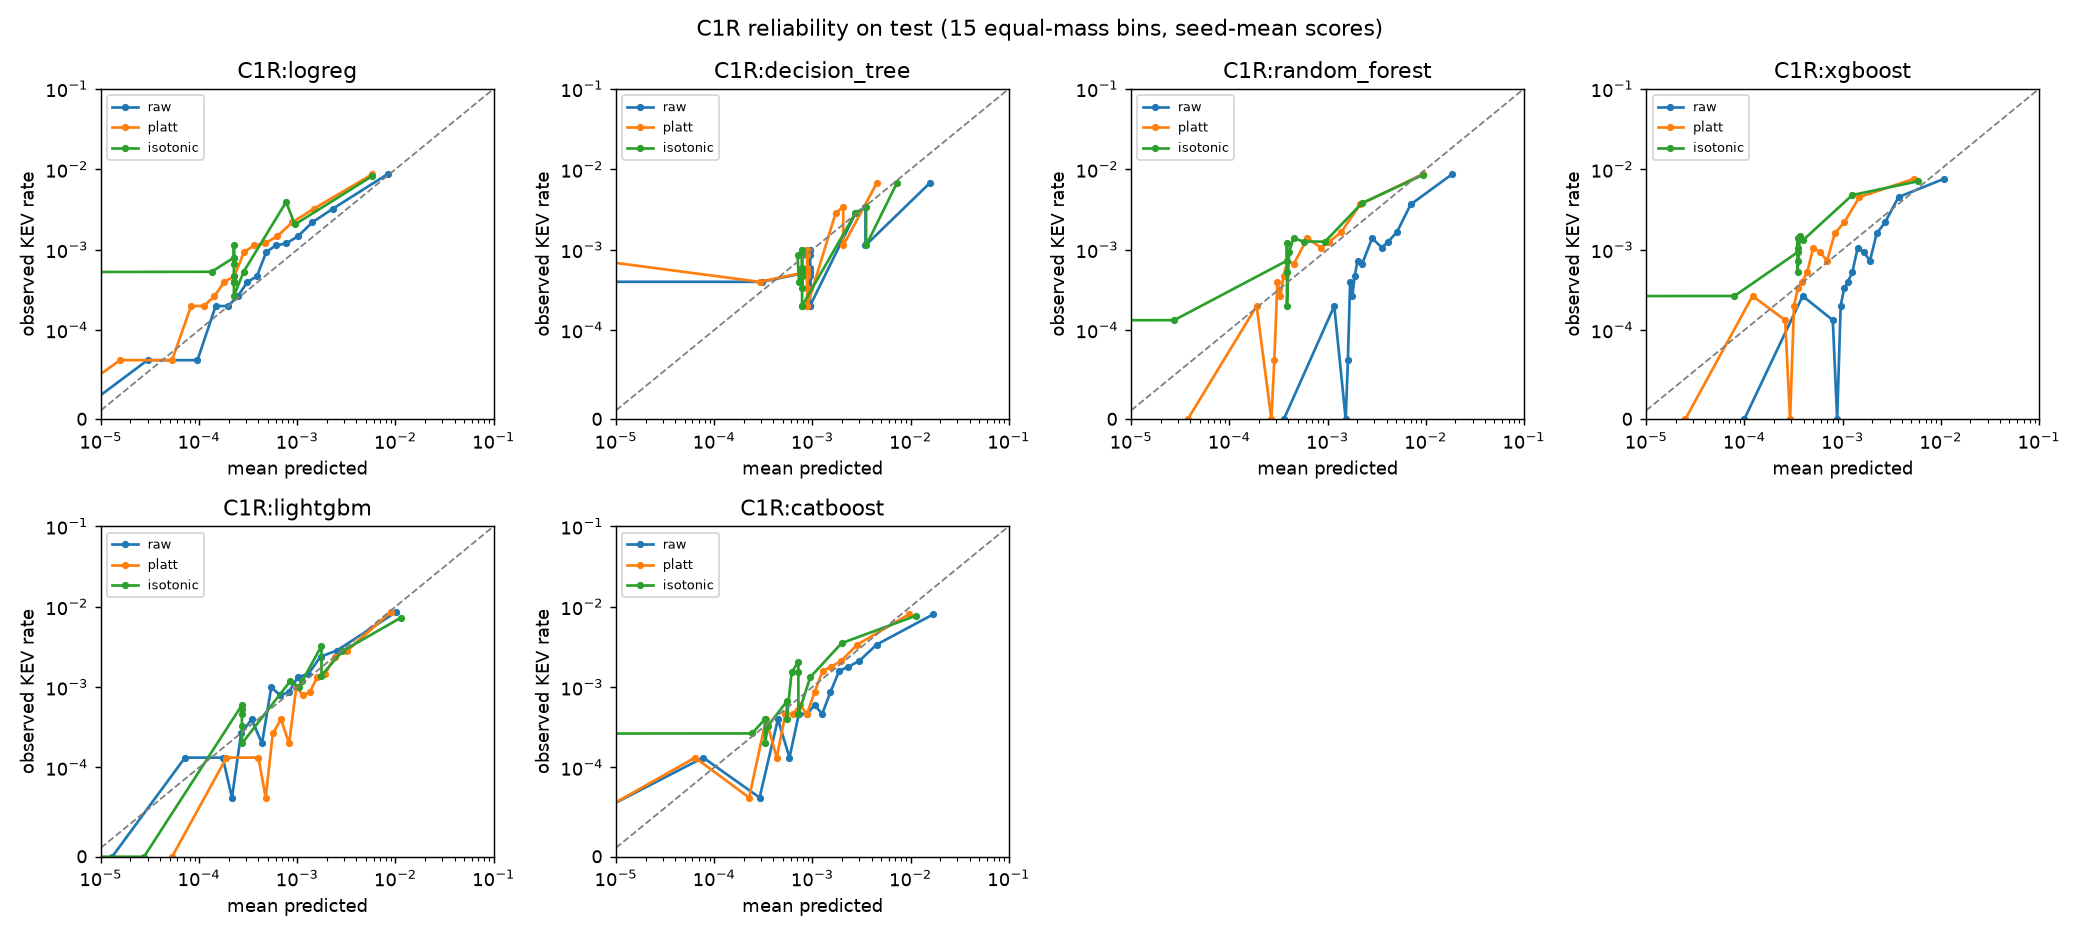

In [4]:
Image("outputs/c5_reliability_c1r.png")

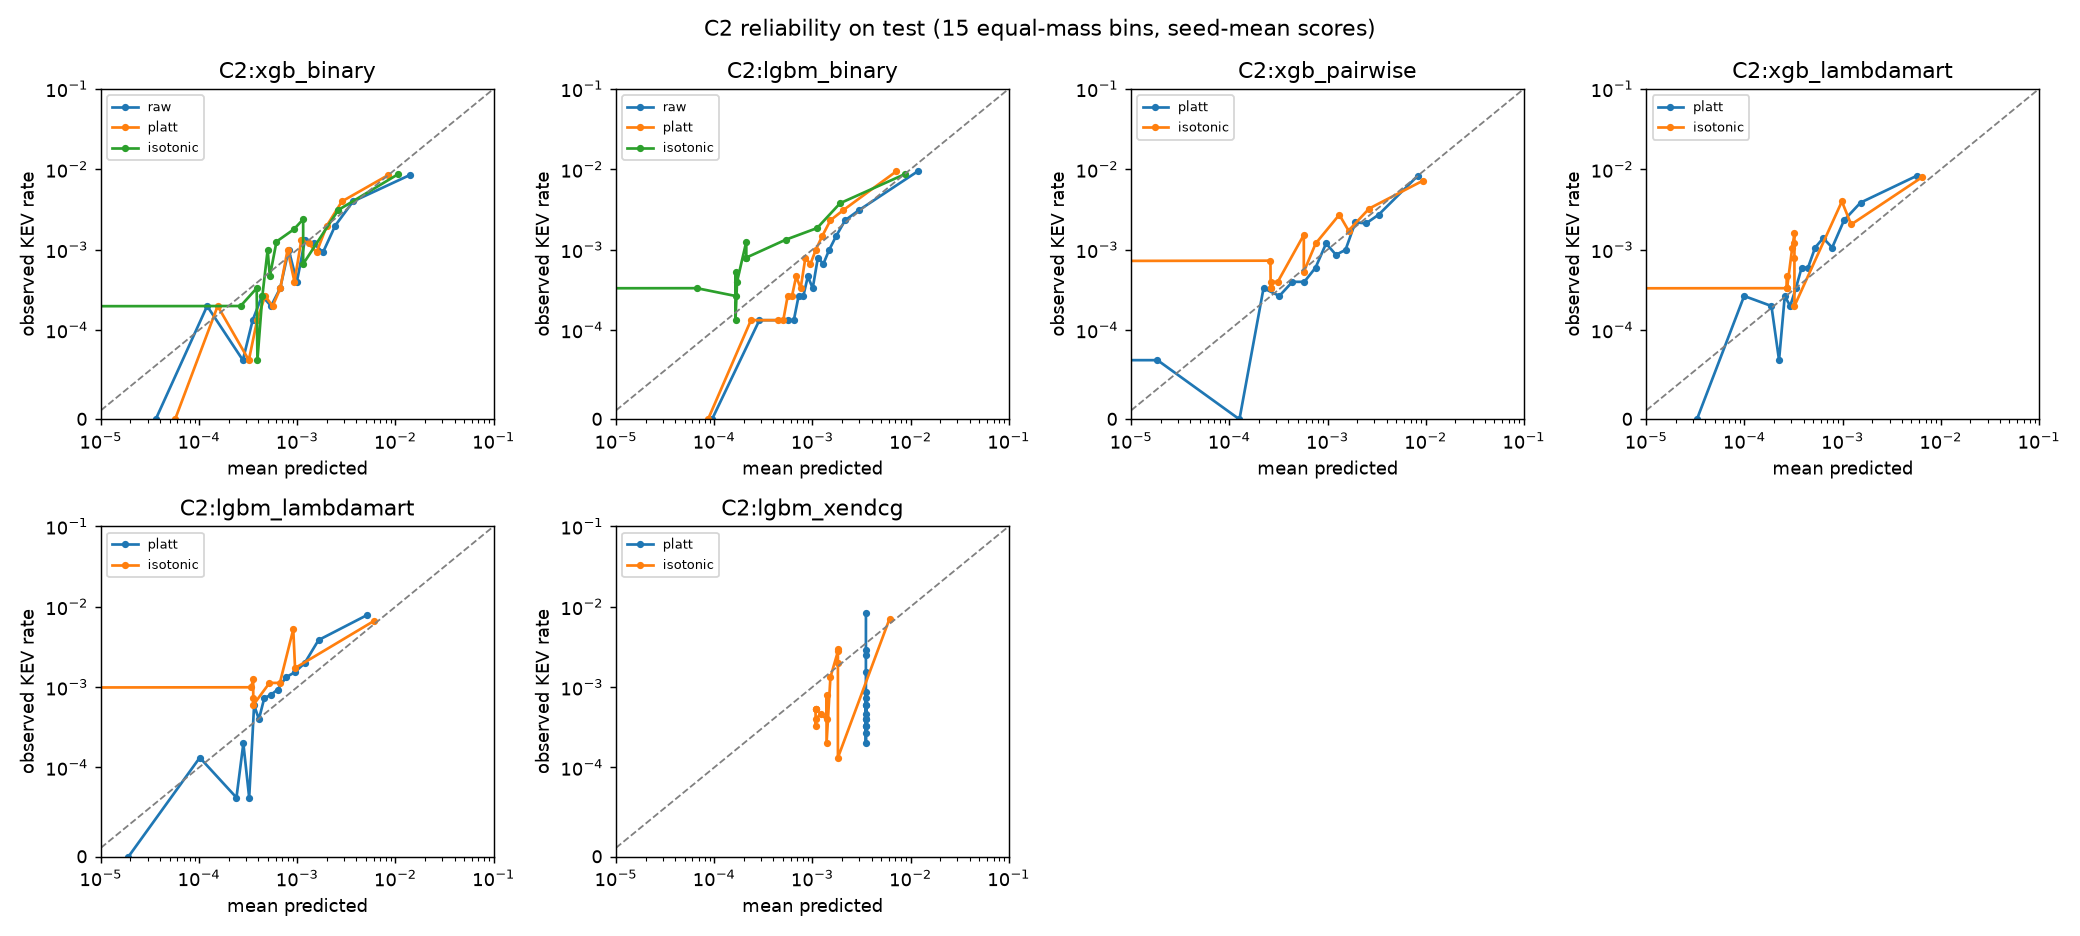

In [5]:
Image("outputs/c5_reliability_c2.png")

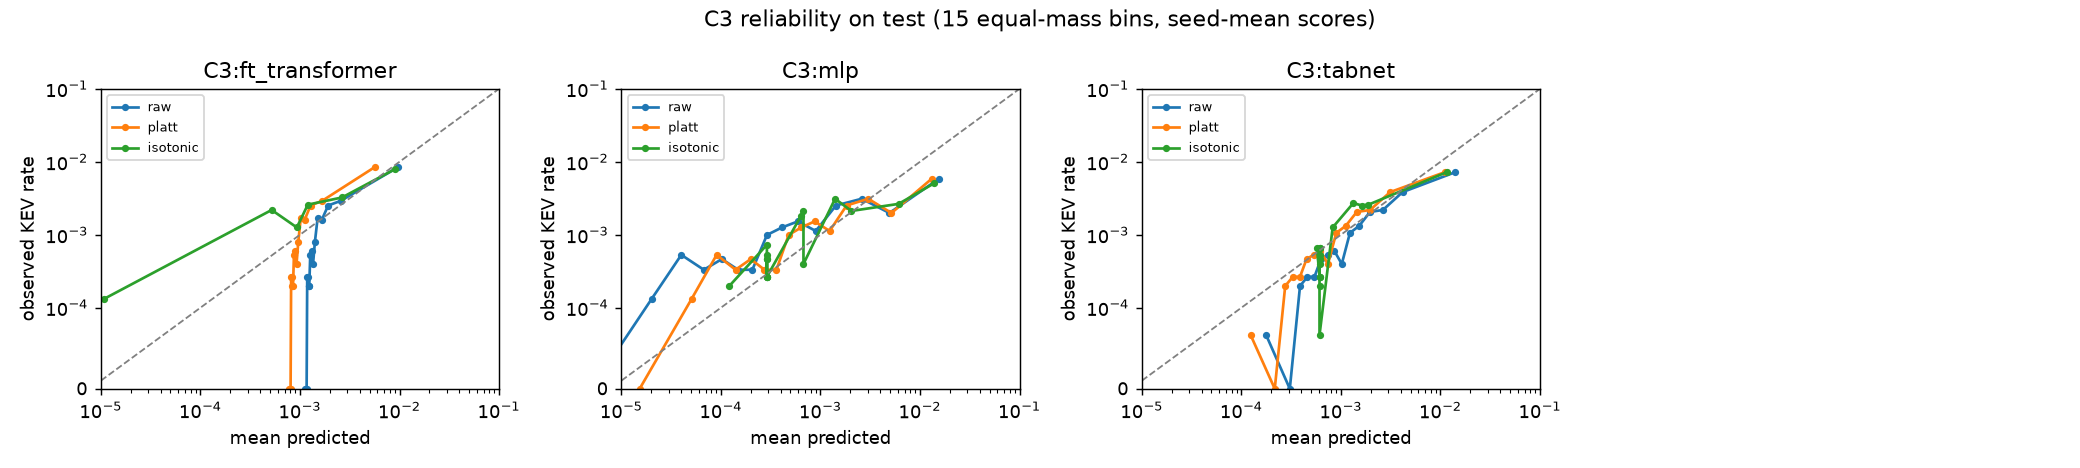

In [6]:
Image("outputs/c5_reliability_c3.png")

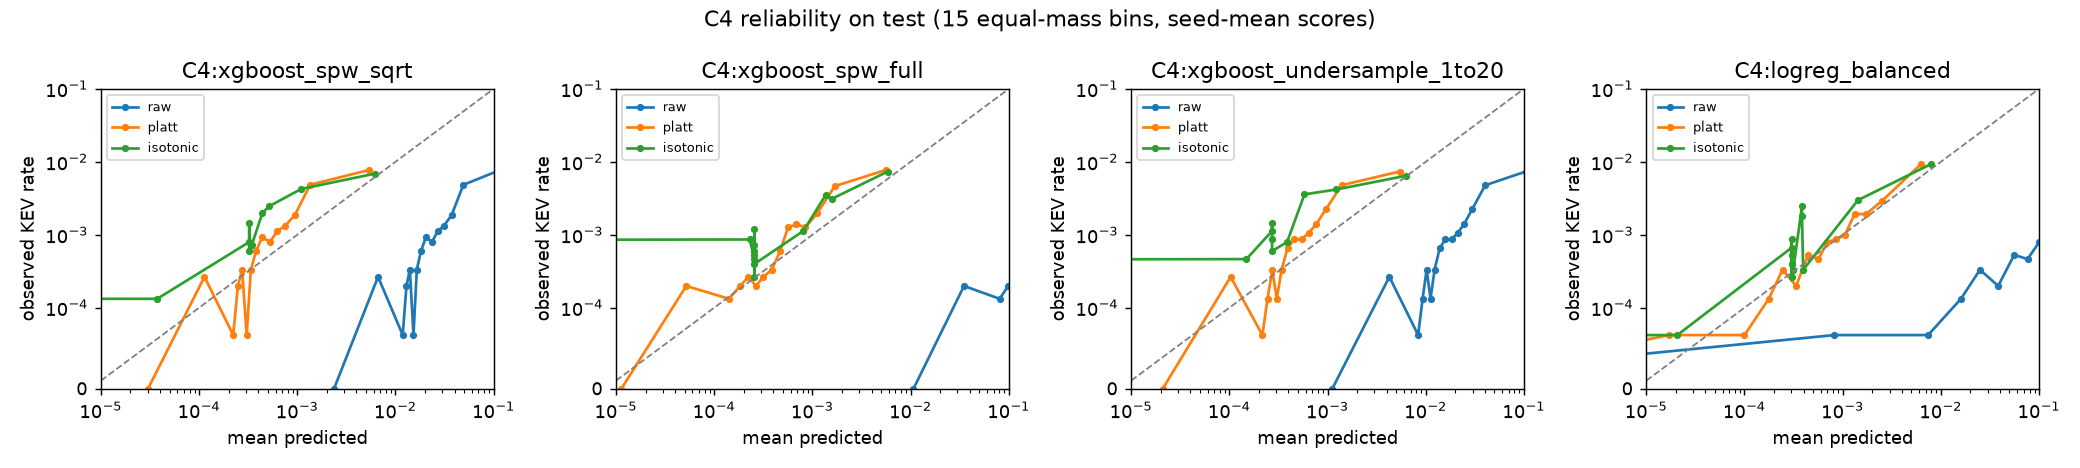

In [7]:
Image("outputs/c5_reliability_c4.png")

**Reading.**
- Unweighted models are already close to calibrated: raw Brier 0.00135–0.00141 vs 0.00136 for a constant base-rate prediction — at this base rate Brier barely separates models; adaptive ECE and the diagrams are more informative.
- **Platt helps where raw scores are visibly off:** decision tree, random forest, CatBoost, TabNet and XGBoost-binary (C2 config) improve significantly; LR, C1-R XGBoost, LightGBM, FT-Transformer and MLP do not (CIs include 0).
- **Class-weighted / undersampled models are badly miscalibrated raw** (mean predicted 2–20% vs 0.14% observed) and Platt fully repairs them (Brier 0.0637 → 0.00135).
- Platt turns ranking-objective scores (LambdaMART, pairwise) into probabilities as good as the pointwise models'.
- **Isotonic lowers PR-AUC** (it creates ties: LR 0.0235 → 0.0201) and is worse than Platt on Brier for the deep models; Platt is the recommended calibrator.
- Caveat: calibrators are learned from a fold model trained on less data than the test model.